In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()
print(f"x_train shape: {x_train.shape}, y_train shape: {y_train.shape}")

x_train shape: (60000, 28, 28), y_train shape: (60000,)


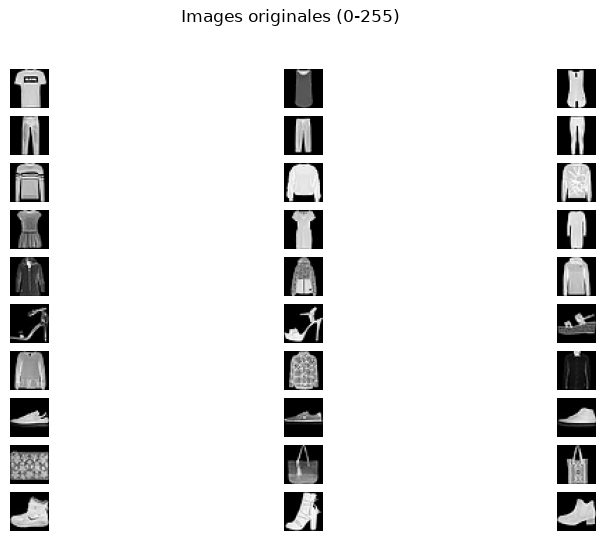

In [3]:
plt.figure(figsize=(10, 6))
for digit in range(10):
    idx = np.where(y_train == digit)[0][:3]  # Trouver l'index du premier exemple du chiffre
    for i, j in enumerate(idx):
        plt.subplot(10, 3, digit*3 + i + 1)
        plt.imshow(x_train[j], cmap='gray')
        plt.axis('off')
plt.suptitle("Images originales (0-255)")
plt.show()

In [8]:
X_train_normalized = x_train.astype("float32") / 255.0
X_test_normalized = x_test.astype("float32") / 255.0

In [10]:
X_train_normalized = np.expand_dims(X_train_normalized, -1)  # Ajouter une dimension pour le canal
X_test_normalized = np.expand_dims(X_test_normalized, -1)  # Ajouter une dimension pour le canal


In [29]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(64, (3, 3), activation='relu'),
#    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
#    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

In [30]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [31]:
history = model.fit(X_train_normalized, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 108s 127ms/step - accuracy: 0.8307 - loss: 0.4835 - val_accuracy: 0.8858 - val_loss: 0.2969
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 105s 124ms/step - accuracy: 0.8906 - loss: 0.3056 - val_accuracy: 0.9072 - val_loss: 0.2479
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 105s 124ms/step - accuracy: 0.9089 - loss: 0.2491 - val_accuracy: 0.9103 - val_loss: 0.2448
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 105s 125ms/step - accuracy: 0.9216 - loss: 0.2132 - val_accuracy: 0.9152 - val_loss: 0.2419
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 105s 125ms/step - accuracy: 0.9336 - loss: 0.1833 - val_accuracy: 0.9195 - val_loss: 0.2271


In [32]:
loss, acc = model.evaluate(X_test_normalized, y_test, verbose=2)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}")

313/313 - 4s - 13ms/step - accuracy: 0.9124 - loss: 0.2494
Test Loss: 0.2494, Test Accuracy: 0.9124


In [33]:
y_pred = np.argmax(model.predict(X_test_normalized), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


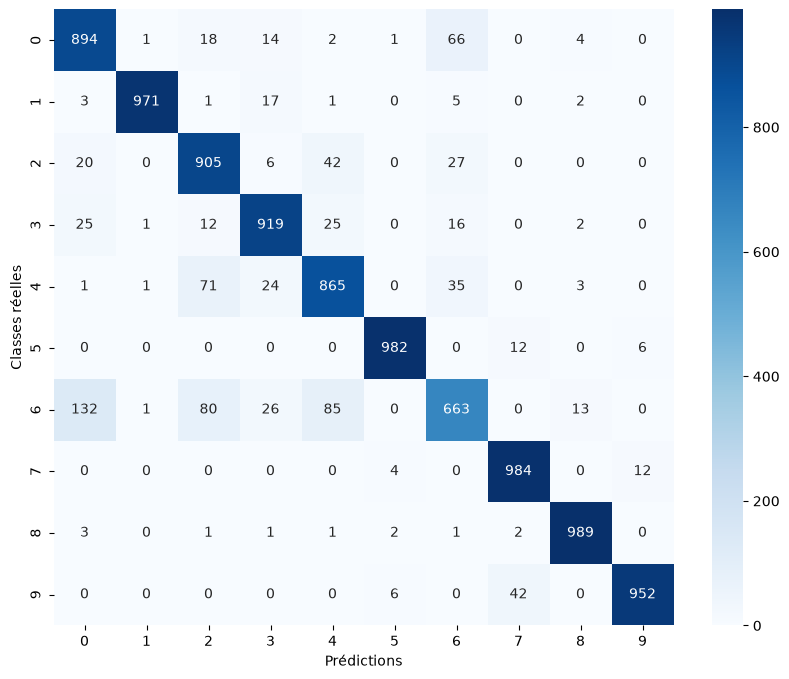

In [35]:
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Prédictions')
plt.ylabel('Classes réelles')
plt.show()

La confusion la plus importante est entre les T-shits/tops (0) et les chemises (6), puis entre les manteaux (4) et les chemises, et entre les pulls (2) et les chemises.